# Structural model: ambient wind + stream arrivals (models.structural)

One forecast equation: an ambient wind level, the current excess relaxing towards it, and
the expected effect of a new stream (first-arrival hazard x peak excess x a rise/decay
profile). All its ~40 parameters are fitted in one optimisation on the official-weighted
loss. Six yearly folds; study `python -m training.structural`; write-up
`docs/structural_model.md`.

In [1]:
import matplotlib.pyplot as plt
import numpy as np
import pandas as pd

from training import model_diagnostics as dg
from training import structural as ts

d = pd.read_csv(ts.EXPERIMENTS / "structural_model.csv", dtype={"fold": str})
ref = d[d.variant == "reference"].set_index("fold")
rows = {}
for v, g in d.groupby("variant"):
    g = g.set_index("fold")
    rel = g["all"] / ref["all"]
    rows[v] = {"/ persistence": np.exp(np.log(g["all"] / g["persistence"]).mean()),
               "vs reference %": 100 * (np.exp(np.log(rel).mean()) - 1),
               "folds won": int((rel < 1).sum()),
               **{f"{r} %": 100 * (np.exp(np.log(g[r] / ref[r]).mean()) - 1)
                  for r in dg.RUN_REGIMES}}
pd.DataFrame(rows).T.sort_values("vs reference %").round(3)

,/ persistence,vs reference %,folds won,CME %,stream arrival %,fast stream %,intermediate %,slow wind %
linear + structural,0.777,-0.299,3.0,0.121,0.062,-3.635,0.889,-1.153
reference,0.779,0.000,0.0,0.000,0.000,0.000,0.000,0.000
no PFSS,0.804,3.111,2.0,5.481,0.645,-1.357,-2.640,1.737
structural,0.814,4.495,2.0,4.162,2.240,7.078,6.558,6.854
fixed decay,0.822,5.464,2.0,4.456,4.399,7.746,7.509,11.096
no arrivals,0.876,12.446,0.0,15.060,13.547,16.897,-1.801,-1.048


## By fold (% change in S_final against the submitted model)

In [2]:
wide = d.pivot(index="fold", columns="variant", values="all")
(100 * (wide.div(wide["reference"], axis=0) - 1)).drop(columns="reference").round(2)

variant,fixed decay,linear + structural,no PFSS,no arrivals,structural
fold,,,,,
2019,-0.29,-3.19,-0.91,15.98,-0.14
2020,-0.98,-2.60,2.21,13.84,-2.71
2021,7.98,0.41,1.28,11.16,7.90
2022,14.54,1.49,9.61,11.09,10.45
2023,0.21,-0.14,7.52,13.01,2.03
2024,12.45,2.37,-0.60,9.70,10.22


## Fitted parameters by fold (stability)

In [3]:
p = pd.read_csv(ts.EXPERIMENTS / "structural_model_params.csv", dtype={"fold": str})
p.set_index(["variant", "fold"]).drop(columns=["restart losses"]).round(3)

loss  rmse_weighted  tau_c0 h  tau_neg h  rise h  \
variant     fold                                                      
structural  2019  0.533         72.990    24.263     24.077     1.0   
            2020  0.482         69.406    27.821     22.993     1.0   
            2021  0.475         68.944    30.545     50.878     1.0   
            2022  0.511         71.461    34.327    145.416     1.0   
            2023  0.578         76.002    36.785     77.284     1.0   
            2024  0.702         83.786    41.979     35.979     1.0   
no arrivals 2019  0.818         90.420    41.950     14.351    12.0   
            2020  0.753         86.765    60.387     14.395    12.0   
            2021  0.738         85.909    54.315     16.150    12.0   
            2022  0.753         86.794    68.004     17.906    12.0   
            2023  0.802         89.542    75.266     19.948    12.0   
            2024  1.007        100.374    79.709     22.531    12.0   
no PFSS     2019  0.561         74.914    23.973     52.873     1.0   
            2020  0.508         71.302    27.667     34.546     1.0   
            2021  0.509         71.335    26.443     61.608     1.0   
            2022  0.532         72.908    30.859    132.747     1.0   
            2023  0.599         77.383    31.670     94.308     1.0   
            2024  0.754         86.846    34.219     51.487     1.0   
fixed decay 2019  0.546         73.884    36.234     22.366     1.0   
            2020  0.493         70.183    42.339     25.835     1.0   
            2021  0.488         69.844    49.796     68.475     1.0   
            2022  0.525         72.436    52.297     62.801     1.0   
            2023  0.596         77.207    40.414     26.261     1.0   
            2024  0.711         84.299    50.013     28.373     1.0   

                  stream decay h  hazard0 /h  amplitude0 km/s  ambient0 km/s  
variant     fold                                                              
structural  2019         104.861       0.011          289.141        354.262  
            2020         124.256       0.009          277.971        326.588  
            2021         135.581       0.009          272.953        327.842  
            2022          50.333       0.005          674.448        308.108  
            2023          49.785       0.004          791.369        292.089  
            2024          61.412       0.004          555.335        327.166  
no arrivals 2019          48.000       0.002          150.000        453.279  
            2020          48.000       0.002          150.000        449.335  
            2021          48.000       0.002          150.000        447.507  
            2022          48.000       0.002          150.000        448.089  
            2023          48.000       0.002          150.000        449.108  
            2024          48.000       0.002          150.000        456.295  
no PFSS     2019          37.971       0.005          738.371        368.845  
            2020          40.075       0.004          745.103        347.017  
            2021          38.601       0.004          837.513        340.433  
            2022          41.698       0.004          795.342        317.708  
            2023          41.310       0.004          844.272        305.199  
            2024          45.466       0.005          768.569        312.617  
fixed decay 2019          81.133       0.006          395.839        374.856  
            2020          73.687       0.005          454.452        341.341  
            2021          75.147       0.005          409.124        339.626  
            2022          54.529       0.004          613.998        321.776  
            2023          50.546       0.004          663.736        326.620  
            2024          65.532       0.003          507.204        340.070

## Decomposition on the 2024 fold (full structural variant)

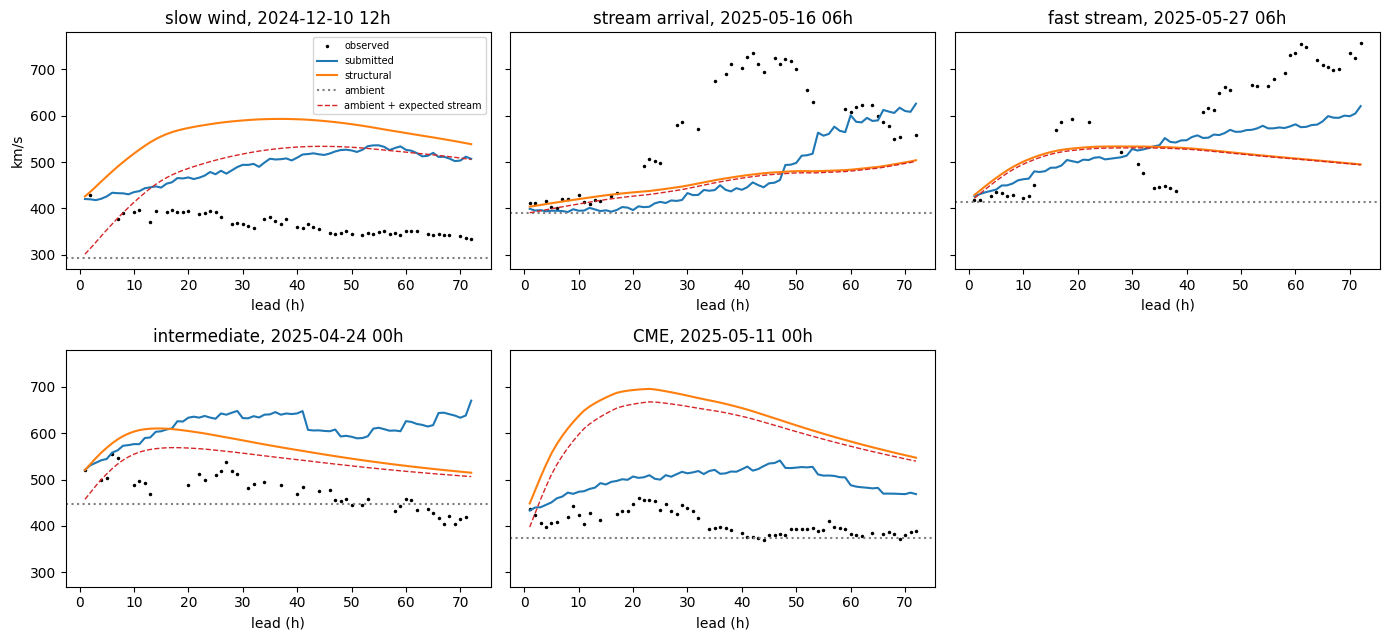

In [4]:
z = np.load(ts.CACHE_DIR / "2024_parts.npz")
t0s = pd.to_datetime(z["t0s"])
regime = z["regime"]
fig, axes = plt.subplots(2, 3, figsize=(14, 6.5), sharey=True)
picks = []
for r in ("slow wind", "stream arrival", "fast stream", "intermediate", "CME"):
    idx = np.flatnonzero(regime == r)
    if len(idx):
        picks.append((r, idx[len(idx) // 2]))
for ax, (r, i) in zip(axes.flat, picks, strict=False):
    k = np.arange(1, 73)
    ax.plot(k, z["obs"][i], "k.", ms=3, label="observed")
    ax.plot(k, z["f_ref"][i], label="submitted")
    ax.plot(k, z["f_struct"][i], label="structural")
    ax.axhline(z["ambient"][i], color="grey", ls=":", label="ambient")
    ax.plot(k, z["ambient"][i] + z["stream"][i], color="C3", ls="--", lw=1,
            label="ambient + expected stream")
    ax.set_title(f"{r}, {t0s[i]:%Y-%m-%d %H}h")
    ax.set_xlabel("lead (h)")
axes.flat[0].legend(fontsize=7)
axes.flat[-1].axis("off")
axes[0, 0].set_ylabel("km/s")
plt.tight_layout()

## Mean forecast and observation by lead and run regime, 2024 fold

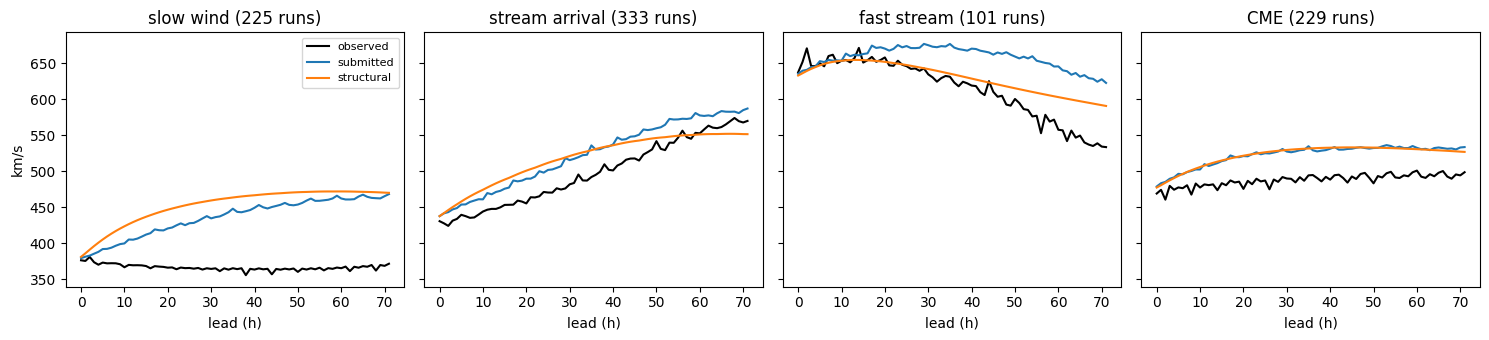

In [5]:
fig, axes = plt.subplots(1, 4, figsize=(15, 3.5), sharey=True)
for ax, r in zip(axes, ("slow wind", "stream arrival", "fast stream", "CME"), strict=True):
    m = regime == r
    ax.plot(np.nanmean(z["obs"][m], 0), "k", label="observed")
    ax.plot(z["f_ref"][m].mean(0), label="submitted")
    ax.plot(z["f_struct"][m].mean(0), label="structural")
    ax.set_title(f"{r} ({m.sum()} runs)")
    ax.set_xlabel("lead (h)")
axes[0].legend(fontsize=8)
axes[0].set_ylabel("km/s")
plt.tight_layout()

## Conclusion: not built

- **Alone, the structural model is 4.5% worse than the submitted linear model** (2 of 6 folds). Without the current-sheet distance it is 3.1% worse. As a regressor in the linear model it is 0.3% better on 3 folds. Nothing meets the 1% / 4-of-6 rule.
- **The fixed shape fits the quiet folds** (2019–2020) but not the active ones (2021, 2022, 2024: +8 to +10%).
- **The rise time hits its 1-hour floor.** Hazard and amplitude trade off from fold to fold, because the expected value only fixes their product.
- **The expected value spreads an uncertain arrival** into a gradual rise, which the linear model's per-lead coefficients already produce.
